# 0. Overview
This notebook benchmarks multiple open-source ASR models across multiple datasets.
It measures:
- **Accuracy**: WER (raw + normalized), CER
- **Failure modes**: insertion/deletion/substitution rates
- **Performance**: mean latency + P95 latency (and optional cold vs warm)
- **Robustness**: tail error rates + dataset sensitivity
At the end, it produces **decision plots** to help pick a model.


# 1. Setup


## 1.1 Imports


In [1]:
import os
import time
from dataclasses import dataclass
from enum import Enum
from typing import Any, Dict, List, Optional, Tuple

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display, HTML
from datasets import Audio, Dataset, load_dataset
import jiwer
from transformers.pipelines import pipeline

/home/hikmat/projects/nls-voice-assistant/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# --- Plot styling ---
sns.set_theme(style="whitegrid")            # modern replacement for set_style
plt.rcParams.update({"figure.figsize": (12, 6)})

In [3]:
print("torch:", torch.__version__)
print("cuda:", torch.cuda.is_available(), "torch_cuda:", torch.version.cuda)
if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

torch: 2.9.1+cu128
cuda: True torch_cuda: 12.8
gpu: NVIDIA GeForce RTX 5060 Ti


# 2. Configuration


## 2.1 Enums


In [4]:
class SampleSize(Enum):
    """Sample size categories"""
    TINY = 10
    SMALL = 25
    MEDIUM = 50
    LARGE = 100
    XLARGE = 250
    XXLARGE = 500
    XXXLARGE = 1000


## 2.2 Preferences


In [5]:
# Test Mode
TEST_ENGLISH_ONLY = True
USE_QUICK_TEST = False
SAMPLE_SIZE = SampleSize.LARGE

# Directories
CACHE_DIR_DATASETS = "data/cached_datasets"
CACHE_DIR_MODELS = None  # None => default HF cache
OUTPUT_DIR = "data/results"


In [6]:
print("=" * 80)
print("PREFERENCES")
print("=" * 80)
print(f"Test mode: {'Quick' if USE_QUICK_TEST else 'Full'}")
print(f"English only: {TEST_ENGLISH_ONLY}")
print(f"Sample size: {SAMPLE_SIZE.name} ({SAMPLE_SIZE.value} samples)")
print("\nDirectories:")
print(f"  Dataset cache: {CACHE_DIR_DATASETS}")
print(f"  Model cache: {CACHE_DIR_MODELS or '~/.cache/huggingface/ (default)'}")
print(f"  Output: {OUTPUT_DIR}")
print("=" * 80)


PREFERENCES
Test mode: Full
English only: True
Sample size: LARGE (100 samples)

Directories:
  Dataset cache: data/cached_datasets
  Model cache: ~/.cache/huggingface/ (default)
  Output: data/results


# 3. Data layer (dataset configs + loading + caching)


## 3.1 DatasetConfig


In [7]:
@dataclass
class DatasetConfig:
    """Configuration for a HuggingFace dataset."""
    name: str
    hf_dataset_name: str
    hf_config: Optional[str] = None
    hf_split: str = "test"
    audio_column: str = "audio"
    text_column: str = "text"
    description: str = ""
    language: str = "en"
    use_streaming: bool = True
    sample_size: Optional[int] = SAMPLE_SIZE.value


## 3.2 Dataset loader + cache


In [8]:
def load_dataset_from_config(config: DatasetConfig) -> Dataset:
    """Load dataset from HuggingFace configuration with optional streaming support."""
    max_samples = config.sample_size
    print(f"📥 Loading {config.name} ({max_samples} samples)... ", end="", flush=True)

    if config.use_streaming:
        from itertools import islice

        dataset_stream = load_dataset(
            config.hf_dataset_name,
            config.hf_config,
            split=config.hf_split,
            streaming=True,
            trust_remote_code=True
        )
        dataset_stream = dataset_stream.shuffle(seed=42, buffer_size=1000)
        samples = list(islice(dataset_stream, max_samples))
        dataset = Dataset.from_list(samples)

        if "audio" in dataset.column_names:
            dataset = dataset.cast_column("audio", Audio())
    else:
        dataset = load_dataset(
            config.hf_dataset_name,
            config.hf_config,
            split=f"{config.hf_split}[:{max_samples}]",
            trust_remote_code=True
        )

    # Normalize column names
    if config.text_column != "text" and config.text_column in dataset.column_names:
        dataset = dataset.rename_column(config.text_column, "text")
    if config.audio_column != "audio" and config.audio_column in dataset.column_names:
        dataset = dataset.rename_column(config.audio_column, "audio")

    # Keep only what we need
    keep = ["audio", "text"]
    to_remove = [c for c in dataset.column_names if c not in keep]
    if to_remove:
        dataset = dataset.remove_columns(to_remove)

    print(f"✓ ({len(dataset)} samples)")
    return dataset


In [9]:
def load_or_create_cached_dataset(config: DatasetConfig, cache_dir: Optional[str] = None) -> Dataset:
    """Load from disk cache or build and cache a processed dataset."""
    cache_dir = cache_dir or CACHE_DIR_DATASETS
    os.makedirs(cache_dir, exist_ok=True)

    cache_path = os.path.join(cache_dir, f"{config.name.lower().replace(' ', '_')}")

    if os.path.exists(cache_path):
        print(f"📂 Loading {config.name} from cache... ", end="", flush=True)
        dataset = Dataset.load_from_disk(cache_path)

        required = config.sample_size
        if required is not None and len(dataset) > required:
            dataset = dataset.select(range(required))
            print(f"✓ ({required} samples)")
        else:
            print(f"✓ ({len(dataset)} samples)")
        return dataset

    dataset = load_dataset_from_config(config)

    if "audio" in dataset.column_names:
        dataset = dataset.cast_column("audio", Audio())

    dataset.save_to_disk(cache_path)
    print(f"💾 Cached to {cache_path}")
    return dataset


# 4. Metrics layer (result schema + normalization + metrics)


## 4.1 ASRResult


In [10]:
@dataclass
class ASRResult:
    """Store results from ASR transcription."""
    model_name: str
    dataset_name: str
    audio_path: str
    transcript: str
    reference_text: str
    time_seconds: float

    # Accuracy
    wer_raw: Optional[float] = None
    wer_norm: Optional[float] = None
    cer: Optional[float] = None

    # Error breakdown (normalized word-level)
    substitutions: Optional[int] = None
    deletions: Optional[int] = None
    insertions: Optional[int] = None
    ref_words: Optional[int] = None
    sub_rate: Optional[float] = None
    del_rate: Optional[float] = None
    ins_rate: Optional[float] = None

    # Runtime diagnostics
    audio_duration_s: Optional[float] = None
    is_cold_start: Optional[bool] = None
    peak_mem_mb: Optional[float] = None

    language: str = "en"

    @property
    def wer_display(self) -> Optional[float]:
        return self.wer_norm if self.wer_norm is not None else self.wer_raw

    def __repr__(self) -> str:
        wer = self.wer_display
        wer_str = f"{wer:.3f}" if isinstance(wer, float) else "N/A"
        cold = " cold" if self.is_cold_start else ""
        return f"ASRResult({self.model_name}, {self.dataset_name},{cold} WER={wer_str}, Time={self.time_seconds:.2f}s)"


## 4.2 WER normalizer


In [11]:
WER_NORMALIZER = jiwer.Compose([
    jiwer.ToLowerCase(),
    jiwer.RemovePunctuation(),
    jiwer.RemoveMultipleSpaces(),
    jiwer.Strip()
])


In [12]:
class ASRMetrics:
    """Pure metric computations (no model calls)."""

    def __init__(self, normalizer=WER_NORMALIZER):
        self.normalizer = normalizer

    def wer(self, reference_text: Optional[str], transcript: str) -> tuple[Optional[float], Optional[float]]:
        """Return (wer_raw, wer_norm)."""
        if not reference_text:
            return None, None

        wer_raw = jiwer.wer(reference_text, transcript)

        ref_n = self.normalizer(reference_text)
        hyp_n = self.normalizer(transcript)
        wer_norm = jiwer.wer(ref_n, hyp_n)

        return float(wer_raw), float(wer_norm)

    def cer(self, reference_text: Optional[str], transcript: str) -> Optional[float]:
        """Return CER (normalized)."""
        if not reference_text:
            return None
        ref_n = self.normalizer(reference_text)
        hyp_n = self.normalizer(transcript)
        return float(jiwer.cer(ref_n, hyp_n))

    def alignment(self, reference_text: Optional[str], transcript: str) -> Dict[str, Optional[float]]:
        """Return insertion/deletion/substitution counts + rates (normalized word-level)."""
        if not reference_text:
            return {
                "substitutions": None, "deletions": None, "insertions": None, "ref_words": None,
                "sub_rate": None, "del_rate": None, "ins_rate": None,
            }

        ref_n = self.normalizer(reference_text)
        hyp_n = self.normalizer(transcript)

        m = jiwer.process_words(ref_n, hyp_n)

        subs = int(getattr(m, "substitutions", 0))
        dels = int(getattr(m, "deletions", 0))
        ins  = int(getattr(m, "insertions", 0))
        hits = int(getattr(m, "hits", 0))

        ref_words = hits + subs + dels  # ✅ reference length (N)

        if ref_words <= 0:
            return {
                "substitutions": subs, "deletions": dels, "insertions": ins, "ref_words": ref_words,
                "sub_rate": None, "del_rate": None, "ins_rate": None,
            }

        return {
            "substitutions": subs,
            "deletions": dels,
            "insertions": ins,
            "ref_words": ref_words,
            "sub_rate": subs / ref_words,
            "del_rate": dels / ref_words,
            "ins_rate": ins / ref_words,
        }



## 4.4 Audio helper (optional RTF)


In [13]:
def _try_audio_duration(audio_input: Any) -> Optional[float]:
    """
    Best-effort duration extraction without heavy IO.
    Works when HF Audio() yields dict with array + sampling_rate.
    """
    try:
        if isinstance(audio_input, dict):
            arr = audio_input.get("array")
            sr = audio_input.get("sampling_rate")
            if arr is not None and sr:
                return float(len(arr) / float(sr))
        return None
    except Exception:
        return None


# 5. Runtime layer (runner + benchmark)


## 5.1 Model runner


In [14]:
class ASRModelRunner:
    """Load/unload a HF ASR pipeline and run inference. No metrics, no dataset loops."""

    def __init__(self, verbose: bool = True, cache_dir: Optional[str] = None):
        self.verbose = verbose
        self.cache_dir = cache_dir
        self.device = "cuda" if torch.cuda.is_available() else "cpu"

        self._pipe = None
        self._model_name = None
        self._first_inference_done = False

    @property
    def model_name(self) -> Optional[str]:
        return self._model_name

    def load(self, model_name: str, model_id: str) -> None:
        if self.verbose:
            print(f"📦 Loading {model_name} ({model_id})... ", end="", flush=True)

        self.unload()

        kwargs = {"device": 0 if self.device == "cuda" else -1}
        if self.cache_dir:
            kwargs["model_kwargs"] = {"cache_dir": self.cache_dir}

        self._pipe = pipeline("automatic-speech-recognition", model=model_id, **kwargs)
        self._model_name = model_name
        self._first_inference_done = False

        if self.verbose:
            print("✓")

    def unload(self) -> None:
        if self._pipe is not None:
            del self._pipe
            self._pipe = None

        self._model_name = None
        self._first_inference_done = False

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    def transcribe(self, audio_input: Any) -> Tuple[str, float, bool, Optional[float], Optional[float]]:
        """
        Returns:
          transcript, elapsed_s, is_cold_start, audio_duration_s, peak_mem_mb
        """
        if self._pipe is None:
            raise ValueError("No model loaded. Call load() first.")

        is_cold_start = not self._first_inference_done

        peak_mem_mb = None
        if torch.cuda.is_available():
            try:
                torch.cuda.reset_peak_memory_stats()
            except Exception:
                pass

        start = time.time()
        out = self._pipe(audio_input)
        elapsed = time.time() - start

        self._first_inference_done = True

        if torch.cuda.is_available():
            try:
                peak_mem_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
            except Exception:
                peak_mem_mb = None

        transcript = (out.get("text") or "").strip()
        audio_duration_s = _try_audio_duration(audio_input)

        return transcript, elapsed, is_cold_start, audio_duration_s, peak_mem_mb


## 5.2 Benchmark runner


In [15]:
class ASRBenchmark:
    """Loops datasets, calls runner, computes metrics, returns ASRResult list."""

    def __init__(
        self,
        runner: ASRModelRunner,
        metrics: Optional[ASRMetrics] = None,
        verbose: bool = True,
        compute_alignment: bool = True,
    ):
        self.runner = runner
        self.metrics = metrics or ASRMetrics()
        self.verbose = verbose
        self.compute_alignment = compute_alignment

    def transcribe_dataset(self, dataset: Dataset, dataset_config: DatasetConfig) -> List[ASRResult]:
        total = len(dataset)
        results: List[ASRResult] = []

        if self.verbose:
            print(f"  🎵 Processing {dataset_config.name} ({total} samples)")

        for idx, item in enumerate(dataset):
            audio_input = self._extract_audio_input(item["audio"])
            reference = item.get("text") or ""

            display_name = self._audio_display_name(item["audio"], dataset_config.name, idx)
            display_path = self._display_path(audio_input, dataset_config.name, idx)

            if self.verbose:
                print(f"    [{idx + 1}/{total}] {display_name}... ", end="", flush=True)

            try:
                transcript, elapsed, is_cold, audio_duration_s, peak_mem_mb = self.runner.transcribe(audio_input)

                wer_raw, wer_norm = self.metrics.wer(reference, transcript)
                cer = self.metrics.cer(reference, transcript)
                align = self.metrics.alignment(reference, transcript) if self.compute_alignment else {}

                r = ASRResult(
                    model_name=self.runner.model_name or "unknown",
                    dataset_name=dataset_config.name,
                    audio_path=display_path,
                    transcript=transcript,
                    reference_text=reference,
                    time_seconds=elapsed,
                    wer_raw=wer_raw,
                    wer_norm=wer_norm,
                    cer=cer,
                    substitutions=align.get("substitutions"),
                    deletions=align.get("deletions"),
                    insertions=align.get("insertions"),
                    ref_words=align.get("ref_words"),
                    sub_rate=align.get("sub_rate"),
                    del_rate=align.get("del_rate"),
                    ins_rate=align.get("ins_rate"),
                    audio_duration_s=audio_duration_s,
                    is_cold_start=is_cold,
                    peak_mem_mb=peak_mem_mb,
                    language=dataset_config.language,
                )

                results.append(r)

                if self.verbose:
                    self._print_result_summary(r)

            except Exception as e:
                if self.verbose:
                    print(f"⚠️ Error: {e}")

        return results

    def _extract_audio_input(self, audio_data: Any) -> Any:
        if isinstance(audio_data, dict):
            if audio_data.get("array") is not None:
                return audio_data
            if audio_data.get("path") is not None:
                return audio_data["path"]
            return audio_data
        return audio_data

    def _display_path(self, audio_input: Any, dataset_name: str, idx: int) -> str:
        if isinstance(audio_input, dict) and audio_input.get("path"):
            return audio_input["path"]
        if isinstance(audio_input, str):
            return audio_input
        return f"{dataset_name}_sample_{idx+1}"

    def _audio_display_name(self, audio_data: Any, dataset_name: str, idx: int) -> str:
        if isinstance(audio_data, dict) and audio_data.get("path"):
            return audio_data["path"]
        return f"{dataset_name}_sample_{idx+1}"

    def _print_result_summary(self, r: ASRResult) -> None:
        wer = r.wer_display
        wer_str = f"{wer:.3f}" if isinstance(wer, float) else "N/A"
        cold = " (cold)" if r.is_cold_start else ""
        print(f"✓{cold} ({r.time_seconds:.2f}s, WER: {wer_str})")


# 6. Models & Datasets


## 6.1 English models + datasets


In [16]:
ENGLISH_MODELS = {
    "Whisper-Small-En": "openai/whisper-small.en",
    "Distil-Whisper-Small-En": "distil-whisper/distil-small.en",
    "Distil-Whisper-Medium-En": "distil-whisper/distil-medium.en",
}

In [17]:
ENGLISH_DATASETS = [
    DatasetConfig(
        name="LibriSpeech_Clean",
        hf_dataset_name="openslr/librispeech_asr",
        hf_config="clean",
        hf_split="test",
        description="Clean audiobook recordings",
        language="en",
    ),
    DatasetConfig(
        name="LibriSpeech_Other",
        hf_dataset_name="openslr/librispeech_asr",
        hf_config="other",
        hf_split="test",
        description="Challenging audiobook recordings",
        language="en",
    ),
    DatasetConfig(
        name="PeoplesSpeech_Clean",
        hf_dataset_name="MLCommons/peoples_speech",
        hf_config="clean",
        hf_split="test",
        text_column="text",
        description="Public speeches (clean audio)",
        language="en",
    ),
    DatasetConfig(
        name="PeoplesSpeech_Dirty",
        hf_dataset_name="MLCommons/peoples_speech",
        hf_config="dirty",
        hf_split="test",
        text_column="text",
        description="Public speeches (challenging audio)",
        language="en",
    ),
    DatasetConfig(
        name="AMI_Meetings",
        hf_dataset_name="edinburghcstr/ami",
        hf_config="ihm",
        hf_split="test",
        description="Meeting recordings - conversational speech",
        language="en",
    ),
]

## 6.2 Multilingual models + datasets


In [18]:
OTHER_MODELS = {
    "Whisper-Small": "openai/whisper-small",
    "HuBERT-Large": "facebook/hubert-large-ls960-ft",
    "Wav2Vec2-Base": "facebook/wav2vec2-base-960h",
    "Wav2Vec2-Large": "facebook/wav2vec2-large-960h-lv60-self",
}

In [19]:
OTHER_LANGUAGE_DATASETS = [
    DatasetConfig(
        name="MLS_German",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="german",
        hf_split="test",
        description="Multilingual LibriSpeech - German audiobooks",
        language="de",
    ),
    DatasetConfig(
        name="MLS_Spanish",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="spanish",
        hf_split="test",
        description="Multilingual LibriSpeech - Spanish audiobooks",
        language="es",
    ),
    DatasetConfig(
        name="MLS_French",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="french",
        hf_split="test",
        description="Multilingual LibriSpeech - French audiobooks",
        language="fr",
    ),
    DatasetConfig(
        name="MLS_Italian",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="italian",
        hf_split="test",
        description="Multilingual LibriSpeech - Italian audiobooks",
        language="it",
    ),
    DatasetConfig(
        name="MLS_Dutch",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="dutch",
        hf_split="test",
        description="Multilingual LibriSpeech - Dutch audiobooks",
        language="nl",
    ),
    DatasetConfig(
        name="MLS_Portuguese",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="portuguese",
        hf_split="test",
        description="Multilingual LibriSpeech - Portuguese audiobooks",
        language="pt",
    ),
    DatasetConfig(
        name="MLS_Polish",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="polish",
        hf_split="test",
        description="Multilingual LibriSpeech - Polish audiobooks",
        language="pl",
    ),
]


## 6.3 Selection logic


In [20]:
SELECTED_MODELS = {**ENGLISH_MODELS, **OTHER_MODELS}

if USE_QUICK_TEST:
    english = ENGLISH_DATASETS[:2]
    other = OTHER_LANGUAGE_DATASETS[:2]
else:
    english = ENGLISH_DATASETS
    other = OTHER_LANGUAGE_DATASETS

SELECTED_DATASETS = english if TEST_ENGLISH_ONLY else (english + other)

print(f"Selected models: {len(SELECTED_MODELS)}")
print(f"Selected datasets: {len(SELECTED_DATASETS)}")


Selected models: 7
Selected datasets: 5


# 7. Run Benchmark


In [21]:
runner = ASRModelRunner(verbose=True, cache_dir=CACHE_DIR_MODELS)
metrics = ASRMetrics(WER_NORMALIZER)
bench = ASRBenchmark(runner, metrics=metrics, verbose=True, compute_alignment=True)

all_results: List[ASRResult] = []

print("🚀 Starting sequential transcription...")
print(f"Device: {runner.device}")
print(f"Model cache: {CACHE_DIR_MODELS or 'Default HF cache'}")
print("=" * 80)


🚀 Starting sequential transcription...
Device: cuda
Model cache: Default HF cache


In [22]:
for model_idx, (model_name, model_id) in enumerate(SELECTED_MODELS.items(), 1):
    print(f"\n{'=' * 80}")
    print(f"MODEL {model_idx}/{len(SELECTED_MODELS)}: {model_name}")
    print(f"{'=' * 80}")

    runner.load(model_name, model_id)

    for dataset_idx, dataset_config in enumerate(SELECTED_DATASETS, 1):
        print(f"\n  Dataset {dataset_idx}/{len(SELECTED_DATASETS)}: {dataset_config.name}")

        try:
            dataset = load_or_create_cached_dataset(dataset_config, cache_dir=CACHE_DIR_DATASETS)

            results = bench.transcribe_dataset(dataset, dataset_config)
            all_results.extend(results)

            if results:
                wer_vals = [r.wer_norm for r in results if isinstance(r.wer_norm, float)]
                avg_wer_norm = float(np.mean(wer_vals)) if wer_vals else float("nan")
                avg_time = float(np.mean([r.time_seconds for r in results]))
                print(f"    ✅ Avg WER (norm): {avg_wer_norm:.3f}, Avg Time: {avg_time:.2f}s")
            else:
                print("    ⚠️ No successful transcriptions")

        except Exception as e:
            print(f"    ⚠️ Error: {str(e)[:140]}")
            continue

    if model_idx < len(SELECTED_MODELS):
        runner.unload()

print(f"\n{'=' * 80}")
print(f"✅ Completed! Total results: {len(all_results)}")
print(f"{'=' * 80}")



MODEL 1/7: Whisper-Small-En
📦 Loading Whisper-Small-En (openai/whisper-small.en)... 

Device set to use cuda:0


✓

  Dataset 1/5: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (100 samples)
  🎵 Processing LibriSpeech_Clean (100 samples)
    [1/100] LibriSpeech_Clean_sample_1... 

`return_token_timestamps` is deprecated for WhisperFeatureExtractor and will be removed in Transformers v5. Use `return_attention_mask` instead, as the number of frames can be inferred from it.
Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.


✓ (cold) (1.72s, WER: 0.000)
    [2/100] LibriSpeech_Clean_sample_2... ✓ (1.30s, WER: 0.000)
    [3/100] LibriSpeech_Clean_sample_3... ✓ (0.39s, WER: 0.000)
    [4/100] LibriSpeech_Clean_sample_4... ✓ (1.79s, WER: 0.000)
    [5/100] LibriSpeech_Clean_sample_5... ✓ (1.03s, WER: 0.032)
    [6/100] LibriSpeech_Clean_sample_6... ✓ (1.60s, WER: 0.000)
    [7/100] LibriSpeech_Clean_sample_7... ✓ (0.95s, WER: 0.000)
    [8/100] LibriSpeech_Clean_sample_8... ✓ (0.36s, WER: 0.000)
    [9/100] LibriSpeech_Clean_sample_9... ✓ (0.40s, WER: 0.000)
    [10/100] LibriSpeech_Clean_sample_10... ✓ (0.80s, WER: 0.042)
    [11/100] LibriSpeech_Clean_sample_11... 

...

✓

  Dataset 1/5: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (100 samples)
  🎵 Processing LibriSpeech_Clean (100 samples)
    [1/100] LibriSpeech_Clean_sample_1... ✓ (cold) (0.05s, WER: 0.000)
    [2/100] LibriSpeech_Clean_sample_2... ✓ (0.08s, WER: 0.023)
    [3/100] LibriSpeech_Clean_sample_3... ✓ (0.03s, WER: 0.000)
    [4/100] LibriSpeech_Clean_sample_4... ✓ (0.13s, WER: 0.000)
    [5/100] LibriSpeech_Clean_sample_5... ✓ (0.06s, WER: 0.032)
    [6/100] LibriSpeech_Clean_sample_6... ✓ (0.07s, WER: 0.000)
    [7/100] LibriSpeech_Clean_sample_7... ✓ (0.04s, WER: 0.000)
    [8/100] LibriSpeech_Clean_sample_8... ✓ (0.03s, WER: 0.000)
    [9/100] LibriSpeech_Clean_sample_9... ✓ (0.03s, WER: 0.000)
    [10/100] LibriSpeech_Clean_sample_10... ✓ (0.04s, WER: 0.000)
    [11/100] LibriSpeech_Clean_sample_11... ✓ (0.03s, WER: 0.000)
    [12/100] LibriSpeech_Clean_sample_12... ✓ (0.03s, WER: 0.000)
    [13/100] LibriSpeech_Clean_sample_13... ✓ (0.03s, WER: 0.000)
    [14/100]

Some weights of Wav2Vec2ForCTC were not initialized from the model checkpoint at facebook/wav2vec2-base-960h and are newly initialized: ['wav2vec2.masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Device set to use cuda:0


✓

  Dataset 1/5: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (100 samples)
  🎵 Processing LibriSpeech_Clean (100 samples)
    [1/100] LibriSpeech_Clean_sample_1... ✓ (cold) (0.03s, WER: 0.000)
    [2/100] LibriSpeech_Clean_sample_2... ✓ (0.03s, WER: 0.023)
    [3/100] LibriSpeech_Clean_sample_3... ✓ (0.02s, WER: 0.000)
    [4/100] LibriSpeech_Clean_sample_4... ✓ (0.06s, WER: 0.031)
    [5/100] LibriSpeech_Clean_sample_5... ✓ (0.02s, WER: 0.032)
    [6/100] LibriSpeech_Clean_sample_6... ✓ (0.03s, WER: 0.000)
    [7/100] LibriSpeech_Clean_sample_7... ✓ (0.02s, WER: 0.000)
    [8/100] LibriSpeech_Clean_sample_8... ✓ (0.02s, WER: 0.000)
    [9/100] LibriSpeech_Clean_sample_9... ✓ (0.02s, WER: 0.000)
    [10/100] LibriSpeech_Clean_sample_10... ✓ (0.02s, WER: 0.042)
    [11/100] LibriSpeech_Clean_sample_11... ✓ (0.02s, WER: 0.000)
    [12/100] LibriSpeech_Clean_sample_12... ✓ (0.02s, WER: 0.000)
    [13/100] LibriSpeech_Clean_sample_13... ✓ (0.02s, WER: 0.000)
    [14/100]

Some weights of Wav2Vec2ForCTC were not initialized from the model checkpoint at facebook/wav2vec2-large-960h-lv60-self and are newly initialized: ['wav2vec2.masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Device set to use cuda:0


✓

  Dataset 1/5: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (100 samples)
  🎵 Processing LibriSpeech_Clean (100 samples)
    [1/100] LibriSpeech_Clean_sample_1... ✓ (cold) (0.04s, WER: 0.000)
    [2/100] LibriSpeech_Clean_sample_2... ✓ (0.08s, WER: 0.000)
    [3/100] LibriSpeech_Clean_sample_3... ✓ (0.03s, WER: 0.000)
    [4/100] LibriSpeech_Clean_sample_4... ✓ (0.13s, WER: 0.000)
    [5/100] LibriSpeech_Clean_sample_5... ✓ (0.06s, WER: 0.032)
    [6/100] LibriSpeech_Clean_sample_6... ✓ (0.07s, WER: 0.000)
    [7/100] LibriSpeech_Clean_sample_7... ✓ (0.04s, WER: 0.000)
    [8/100] LibriSpeech_Clean_sample_8... ✓ (0.03s, WER: 0.000)
    [9/100] LibriSpeech_Clean_sample_9... ✓ (0.03s, WER: 0.000)
    [10/100] LibriSpeech_Clean_sample_10... ✓ (0.04s, WER: 0.042)
    [11/100] LibriSpeech_Clean_sample_11... ✓ (0.02s, WER: 0.000)
    [12/100] LibriSpeech_Clean_sample_12... ✓ (0.03s, WER: 0.000)
    [13/100] LibriSpeech_Clean_sample_13... ✓ (0.03s, WER: 0.000)
    [14/100]

# 8. Analysis & Plots (modular + deciding plots at end)


## 8.1 Small helpers


In [23]:
def _minmax(s: pd.Series) -> pd.Series:
    s = pd.to_numeric(s, errors="coerce")
    rng = s.max() - s.min()
    if pd.isna(rng) or rng == 0:
        return pd.Series(0.0, index=s.index)
    return (s - s.min()) / rng

def _has_cols(df: pd.DataFrame, cols: List[str]) -> bool:
    return all(c in df.columns for c in cols)


## 8.2 Analyzer (semantic plotting methods)


In [24]:
@dataclass
class PlotConfig:
    figure_width: float = 12
    figure_height: float = 6
    grid_alpha: float = 0.25
    bar_alpha: float = 0.85
    tail_wer_thresholds: Tuple[float, ...] = (0.5, 1.0)
    top_n: int = 10

@dataclass
class ColorConfig:
    heatmap_wer: str = "RdYlGn_r"
    heatmap_time: str = "Blues"


In [25]:
class ASRModelAnalyzer:
    """Analyze and visualize ASR results (modular plots)."""

    def __init__(self, plot_config: Optional[PlotConfig] = None, color_config: Optional[ColorConfig] = None):
        self.cfg = plot_config or PlotConfig()
        self.colors = color_config or ColorConfig()

    def results_to_dataframe(self, results: List[ASRResult]) -> pd.DataFrame:
        return pd.DataFrame([{
            "model": r.model_name,
            "dataset": r.dataset_name,
            "language": r.language,
            "audio_path": r.audio_path,
            "reference": r.reference_text,
            "transcript": r.transcript,
            "time_s": r.time_seconds,
            "wer_norm": r.wer_norm,
            "wer_raw": r.wer_raw,
            "cer": r.cer,
            "del_rate": r.del_rate,
            "ins_rate": r.ins_rate,
            "sub_rate": r.sub_rate,
            "is_cold_start": r.is_cold_start,
            "peak_mem_mb": r.peak_mem_mb,
            "audio_duration_s": r.audio_duration_s,
        } for r in results])

    # ---------- Summary ----------
    def display_summary_tables(self, df: pd.DataFrame, dataset_order_mode: str = "as_config") -> None:
        display(HTML("<h3>📊 Model×Dataset Summary (Models ordered by overall performance)</h3>"))

        # --- Dataset order (simple) ---
        as_seen = df["dataset"].drop_duplicates().tolist()
        if dataset_order_mode == "as_config":
            try:
                configured = [cfg.name for cfg in SELECTED_DATASETS]  # type: ignore[name-defined]
                dataset_order = [d for d in configured if d in as_seen] + [d for d in as_seen if d not in configured]
            except Exception:
                dataset_order = as_seen
        else:
            dataset_order = as_seen  # fallback for "as_seen" and any other value

        # --- Model order by overall performance (lower WER_norm is better) ---
        overall = df.groupby("model", sort=False)["wer_norm"].mean().sort_values()
        model_order = overall.index.tolist()

        # Force ordering via categoricals
        df2 = df.copy()
        df2["model"] = pd.Categorical(df2["model"], categories=model_order, ordered=True)
        df2["dataset"] = pd.Categorical(df2["dataset"], categories=dataset_order, ordered=True)

        cer_col = "cer" if "cer" in df2.columns else "wer_norm"

        summary = (
            df2.groupby(["model", "dataset"], sort=False)
               .agg(
                   language=("language", "first"),
                   wer_norm_mean=("wer_norm", "mean"),
                   wer_norm_std=("wer_norm", "std"),
                   wer_raw_mean=("wer_raw", "mean"),
                   wer_raw_std=("wer_raw", "std"),
                   cer_mean=(cer_col, "mean"),
                   time_mean=("time_s", "mean"),
                   time_p95=("time_s", lambda s: s.quantile(0.95)),
                   n=("wer_norm", "count"),
               )
               .round(4)
        )

        # Ensure consistent dataset rows under each model (even if missing)
        full_index = pd.MultiIndex.from_product([model_order, dataset_order], names=["model", "dataset"])
        summary = summary.reindex(full_index)

        display(HTML("<h4>🏆 Overall model ranking (by mean WER_norm)</h4>"))
        overall_table = pd.DataFrame({"wer_norm_mean": overall.round(4)})
        display(overall_table.style.background_gradient(cmap=self.colors.heatmap_wer, subset=["wer_norm_mean"]))

        display(
            summary.style
                  .background_gradient(cmap=self.colors.heatmap_wer, subset=["wer_norm_mean"])
                  .format(na_rep="")
        )


    # ---------- Accuracy ----------
    def plot_accuracy(self, df: pd.DataFrame) -> None:
        if not _has_cols(df, ["model", "wer_norm"]):
            print("Accuracy plots skipped (missing: model/wer_norm).")
            return

        agg = df.groupby("model").agg(
            wer_norm_mean=("wer_norm", "mean"),
            wer_norm_std=("wer_norm", "std"),
        ).sort_values("wer_norm_mean")

        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        ax.barh(agg.index, agg["wer_norm_mean"], xerr=agg["wer_norm_std"], alpha=self.cfg.bar_alpha)
        ax.set_title("WER (normalized) by model (lower is better)")
        ax.set_xlabel("WER_norm")
        ax.grid(axis="x", alpha=self.cfg.grid_alpha)
        ax.invert_yaxis()
        plt.show()

        if "cer" in df.columns and not df["cer"].isna().all():
            cer = df.groupby("model")["cer"].mean().sort_values()
            fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
            ax.barh(cer.index, cer.values, alpha=self.cfg.bar_alpha)
            ax.set_title("CER (normalized) by model (lower is better)")
            ax.set_xlabel("CER")
            ax.grid(axis="x", alpha=self.cfg.grid_alpha)
            ax.invert_yaxis()
            plt.show()

    # ---------- Speed ----------
    def plot_speed(self, df: pd.DataFrame) -> None:
        if not _has_cols(df, ["model", "time_s"]):
            print("Speed plots skipped (missing: model/time_s).")
            return

        agg = df.groupby("model").agg(
            time_p95=("time_s", lambda s: s.quantile(0.95)),
            time_mean=("time_s", "mean"),
        ).sort_values("time_p95")

        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        ax.barh(agg.index, agg["time_p95"], alpha=self.cfg.bar_alpha)
        ax.set_title("P95 latency by model (lower is better)")
        ax.set_xlabel("Seconds")
        ax.grid(axis="x", alpha=self.cfg.grid_alpha)
        ax.invert_yaxis()
        plt.show()

        top_order = agg.index.tolist()[: self.cfg.top_n]
        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        sns.boxplot(data=df[df["model"].isin(top_order)], x="time_s", y="model", order=top_order, ax=ax)
        ax.set_title(f"Latency distribution (boxplot) — top {len(top_order)} by P95")
        ax.set_xlabel("Seconds")
        ax.set_ylabel("")
        ax.grid(axis="x", alpha=self.cfg.grid_alpha)
        plt.show()

        if "is_cold_start" in df.columns and not df["is_cold_start"].isna().all():
            cold = df[df["is_cold_start"] == True].groupby("model")["time_s"].mean()
            warm = df[df["is_cold_start"] == False].groupby("model")["time_s"].mean()
            both = pd.DataFrame({"cold_mean": cold, "warm_mean": warm}).dropna()

            if not both.empty:
                both = both.sort_values("cold_mean")
                fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
                ax.barh(both.index, both["cold_mean"], alpha=0.7, label="cold mean")
                ax.barh(both.index, both["warm_mean"], alpha=0.7, label="warm mean")
                ax.set_title("Cold vs Warm mean latency (if available)")
                ax.set_xlabel("Seconds")
                ax.grid(axis="x", alpha=self.cfg.grid_alpha)
                ax.legend()
                ax.invert_yaxis()
                plt.show()

    # ---------- Failure modes ----------
    def plot_failure_modes(self, df: pd.DataFrame) -> None:
        need = ["model", "del_rate", "ins_rate", "sub_rate"]
        if not all(c in df.columns for c in need):
            print("Failure-mode plots skipped (missing del_rate/ins_rate/sub_rate). "
                  "Make sure compute_alignment=True in ASRBenchmark.")
            return

        df2 = df.copy()
        for c in ["del_rate", "ins_rate", "sub_rate"]:
            df2[c] = pd.to_numeric(df2[c], errors="coerce")

        agg = (
            df2.groupby("model", sort=False)[["del_rate", "ins_rate", "sub_rate"]]
               .mean()
               .fillna(0.0)
        )

        # Sort by total error rate (so most problematic is bottom/top consistently)
        agg["total"] = agg["del_rate"] + agg["ins_rate"] + agg["sub_rate"]
        agg = agg.sort_values("total").drop(columns=["total"])

        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        agg.plot(kind="barh", stacked=True, ax=ax)
        ax.set_title("Error breakdown (mean rates): deletion / insertion / substitution (lower is better)")
        ax.set_xlabel("Rate (relative to reference words)")
        ax.grid(axis="x", alpha=self.cfg.grid_alpha)
        plt.show()


    # ---------- Robustness ----------
    def plot_robustness(self, df: pd.DataFrame) -> None:
        if not _has_cols(df, ["model", "wer_norm"]):
            print("Robustness plots skipped (missing: model/wer_norm).")
            return

        g = df.groupby("model")["wer_norm"]
        tail = pd.DataFrame({f"WER>{thr:g}": g.apply(lambda s: (s > thr).mean()) for thr in self.cfg.tail_wer_thresholds})
        tail = tail.sort_values(tail.columns[0])

        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        tail.plot(kind="barh", ax=ax)
        ax.set_title("Tail error rates by model (lower is better)")
        ax.set_xlabel("Fraction of samples")
        ax.grid(axis="x", alpha=self.cfg.grid_alpha)
        plt.show()

        if _has_cols(df, ["model", "dataset", "wer_norm"]):
            pivot = df.pivot_table(values="wer_norm", index="model", columns="dataset", aggfunc="mean")
            sensitivity = pivot.std(axis=1).sort_values()
            fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
            ax.barh(sensitivity.index, sensitivity.values, alpha=self.cfg.bar_alpha)
            ax.set_title("Dataset sensitivity: std of mean WER across datasets (lower is better)")
            ax.set_xlabel("Std dev of dataset means")
            ax.grid(axis="x", alpha=self.cfg.grid_alpha)
            ax.invert_yaxis()
            plt.show()

    # ---------- Heatmaps ----------
    def plot_heatmaps(self, df: pd.DataFrame) -> None:
        if not _has_cols(df, ["model", "dataset", "wer_norm", "time_s"]):
            print("Heatmaps skipped (missing: model/dataset/wer_norm/time_s).")
            return

        wer_p = df.pivot_table(values="wer_norm", index="model", columns="dataset", aggfunc="mean")
        time_p = df.pivot_table(values="time_s", index="model", columns="dataset", aggfunc="mean")

        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        sns.heatmap(wer_p, annot=True, fmt=".3f", cmap=self.colors.heatmap_wer, ax=ax)
        ax.set_title("WER_norm heatmap (mean)")
        plt.show()

        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        sns.heatmap(time_p, annot=True, fmt=".2f", cmap=self.colors.heatmap_time, ax=ax)
        ax.set_title("Inference time heatmap (mean)")
        plt.show()

    # ---------- Tradeoffs ----------
    def plot_tradeoffs(self, df: pd.DataFrame) -> None:
        if not _has_cols(df, ["model", "wer_norm", "time_s"]):
            print("Trade-off plots skipped (missing: model/wer_norm/time_s).")
            return

        agg = df.groupby("model").agg(
            wer=("wer_norm", "mean"),
            time_mean=("time_s", "mean"),
            time_p95=("time_s", lambda s: s.quantile(0.95)),
        )

        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        ax.scatter(agg["time_mean"], agg["wer"])
        for m, row in agg.iterrows():
            ax.annotate(m, (row["time_mean"], row["wer"]), fontsize=8, alpha=0.8)
        ax.set_title("Accuracy vs Mean Latency (lower-left is better)")
        ax.set_xlabel("Mean latency (s)")
        ax.set_ylabel("WER_norm")
        ax.grid(alpha=self.cfg.grid_alpha)
        plt.show()

        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        ax.scatter(agg["time_p95"], agg["wer"])
        for m, row in agg.iterrows():
            ax.annotate(m, (row["time_p95"], row["wer"]), fontsize=8, alpha=0.8)
        ax.set_title("Accuracy vs P95 Latency (lower-left is better)")
        ax.set_xlabel("P95 latency (s)")
        ax.set_ylabel("WER_norm")
        ax.grid(alpha=self.cfg.grid_alpha)
        plt.show()

    # ---------- Deciding plots ----------
    def plot_decision_plots(self, df: pd.DataFrame) -> None:
        if not _has_cols(df, ["model", "wer_norm", "time_s"]):
            print("Decision plots skipped (missing: model/wer_norm/time_s).")
            return

        g = df.groupby("model")
        thr0 = self.cfg.tail_wer_thresholds[0] if self.cfg.tail_wer_thresholds else 0.5

        agg = pd.DataFrame({
            "wer": g["wer_norm"].mean(),
            "p95": g["time_s"].quantile(0.95),
            "tail": g["wer_norm"].apply(lambda s: (s > thr0).mean()),
        })

        if "del_rate" in df.columns:
            agg["del"] = g["del_rate"].mean()
        if "cer" in df.columns:
            agg["cer"] = g["cer"].mean()

        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        ax.scatter(agg["p95"], agg["wer"])
        for m, row in agg.iterrows():
            ax.annotate(m, (row["p95"], row["wer"]), fontsize=8, alpha=0.85)
        ax.set_title("DECISION: WER vs P95 latency (lower-left is best)")
        ax.set_xlabel("P95 latency (s)")
        ax.set_ylabel("WER_norm")
        ax.grid(alpha=self.cfg.grid_alpha)
        plt.show()

        score = (
            0.55 * _minmax(agg["wer"]) +
            0.35 * _minmax(agg["p95"]) +
            0.10 * _minmax(agg["tail"])
        )
        board = score.sort_values()

        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        ax.barh(board.index, board.values, alpha=self.cfg.bar_alpha)
        ax.set_title("DECISION: Combined score (WER + P95 + tail). Lower is better")
        ax.set_xlabel("Score")
        ax.grid(axis="x", alpha=self.cfg.grid_alpha)
        ax.invert_yaxis()
        plt.show()

        cols = ["tail"]
        if "del" in agg.columns:
            cols.append("del")
        if "cer" in agg.columns:
            cols.append("cer")

        safety = agg[cols].sort_values(cols[0])
        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        safety.plot(kind="barh", ax=ax)
        ax.set_title("DECISION: Robustness / failure indicators (lower is better)")
        ax.set_xlabel("Value")
        ax.grid(axis="x", alpha=self.cfg.grid_alpha)
        plt.show()


## 8.3 Build DataFrame + run plots


In [26]:
analyzer = ASRModelAnalyzer()
df = analyzer.results_to_dataframe(all_results)

/tmp/ipykernel_19069/1761417822.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df2.groupby(["model", "dataset"], sort=False)


,wer_norm_mean
model,
Distil-Whisper-Medium-En,0.175600
Distil-Whisper-Small-En,0.178100
Whisper-Small-En,0.202800
Whisper-Small,0.215700
Wav2Vec2-Large,0.280300
HuBERT-Large,0.314500
Wav2Vec2-Base,0.348300


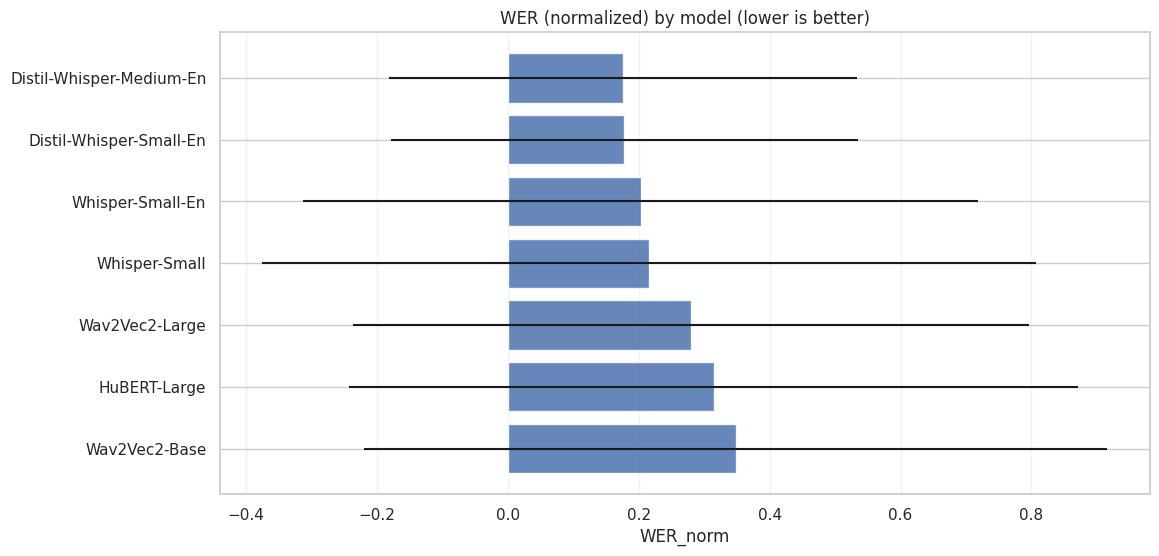

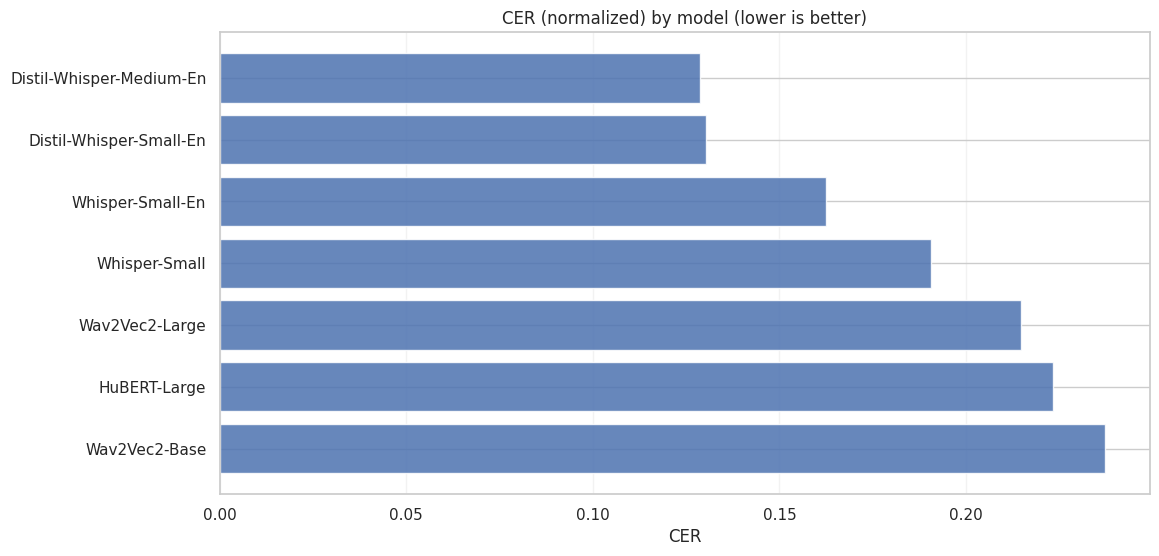

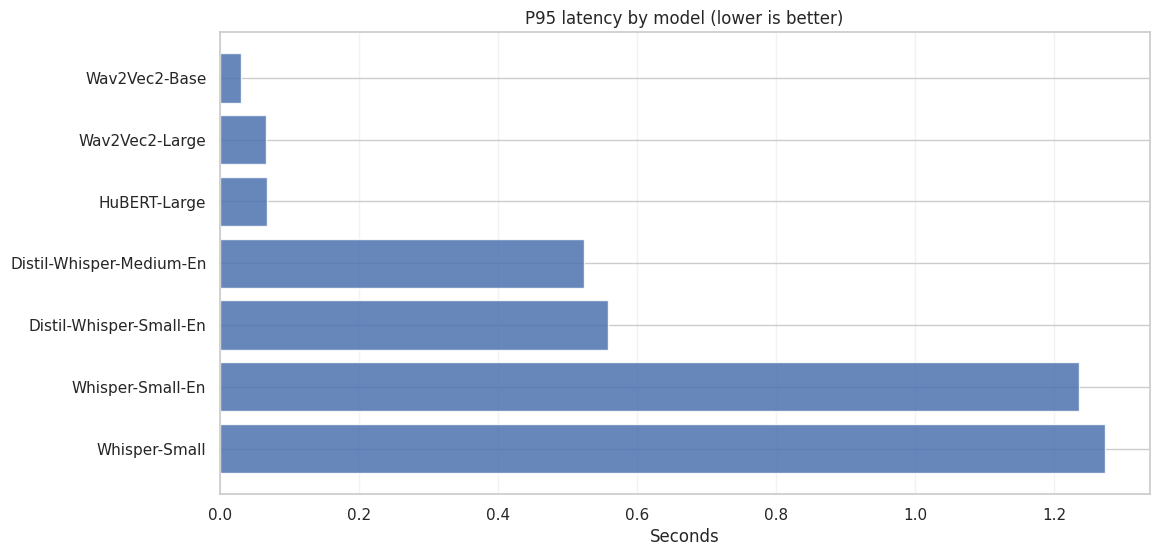

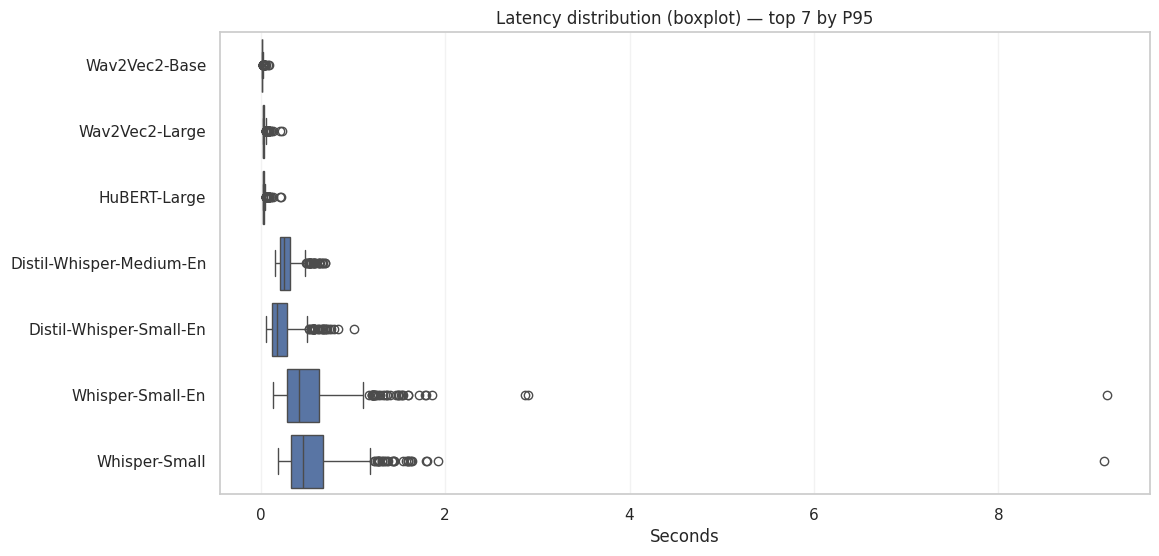

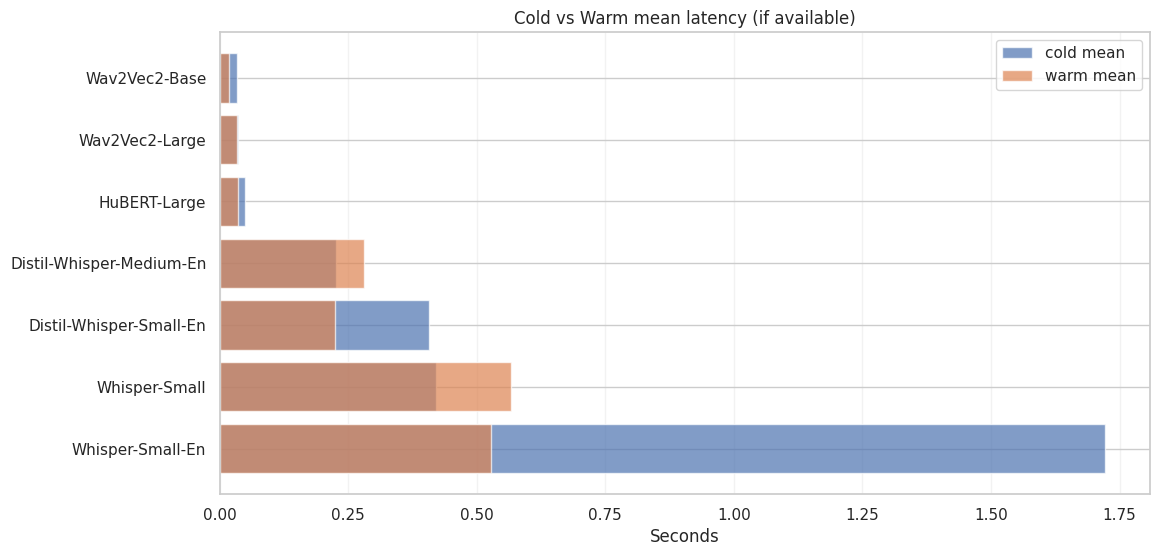

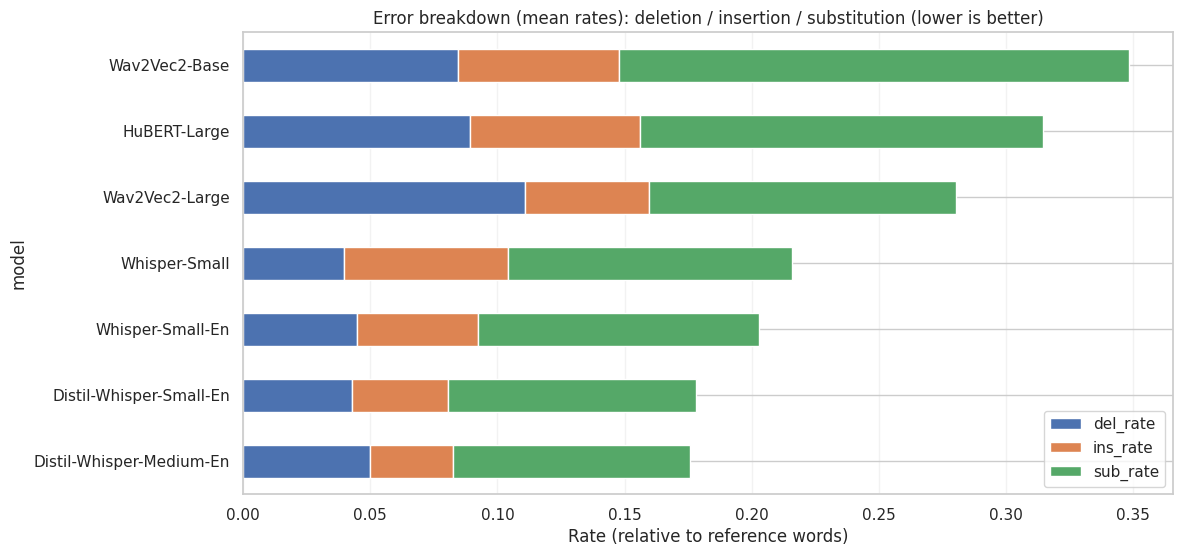

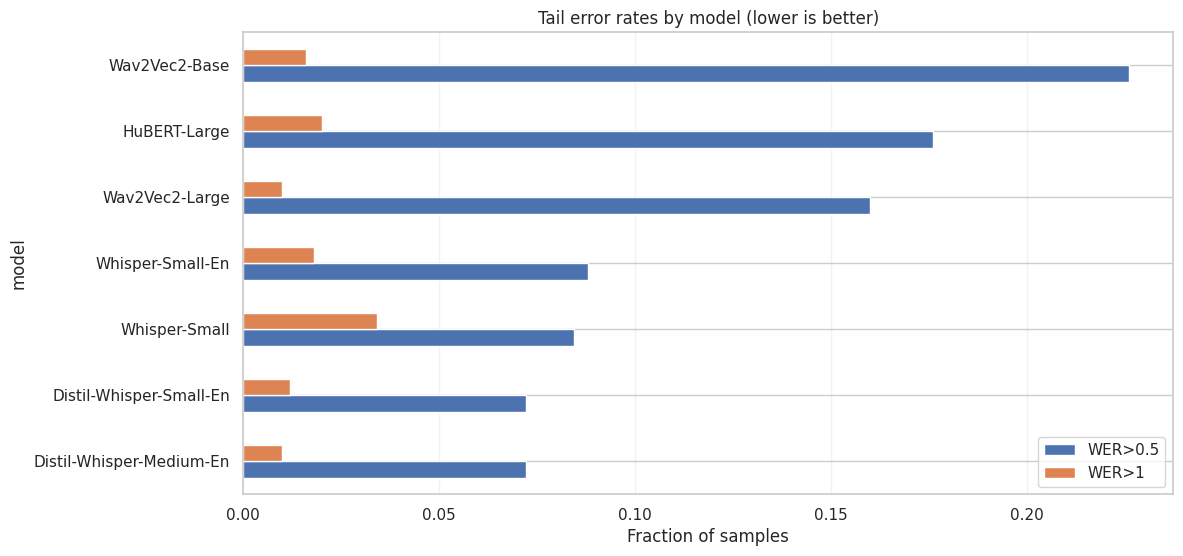

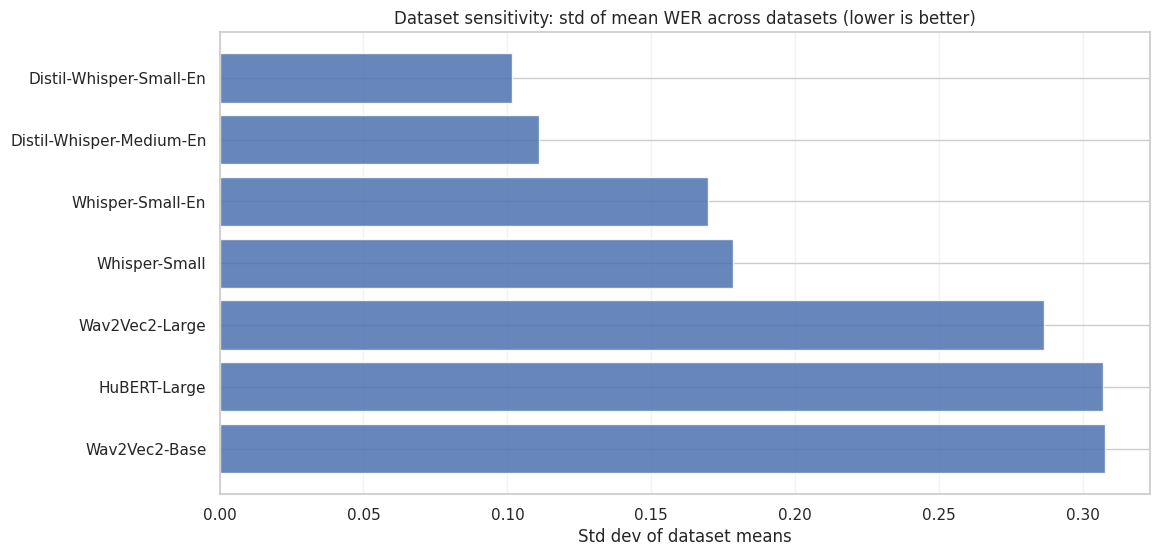

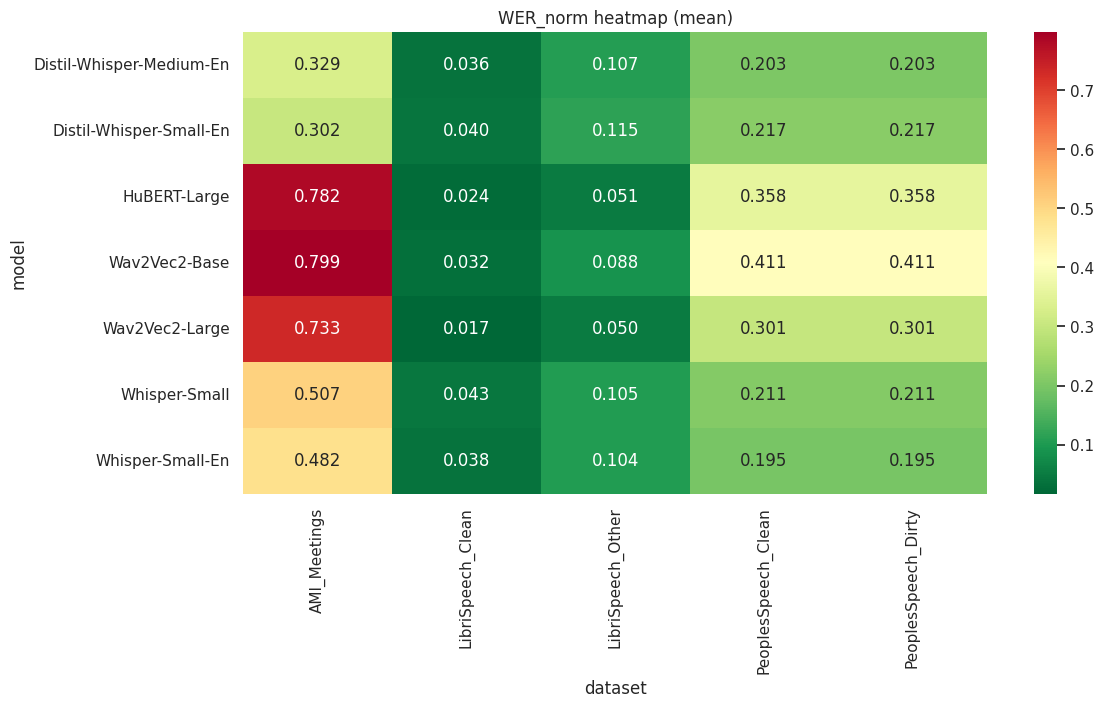

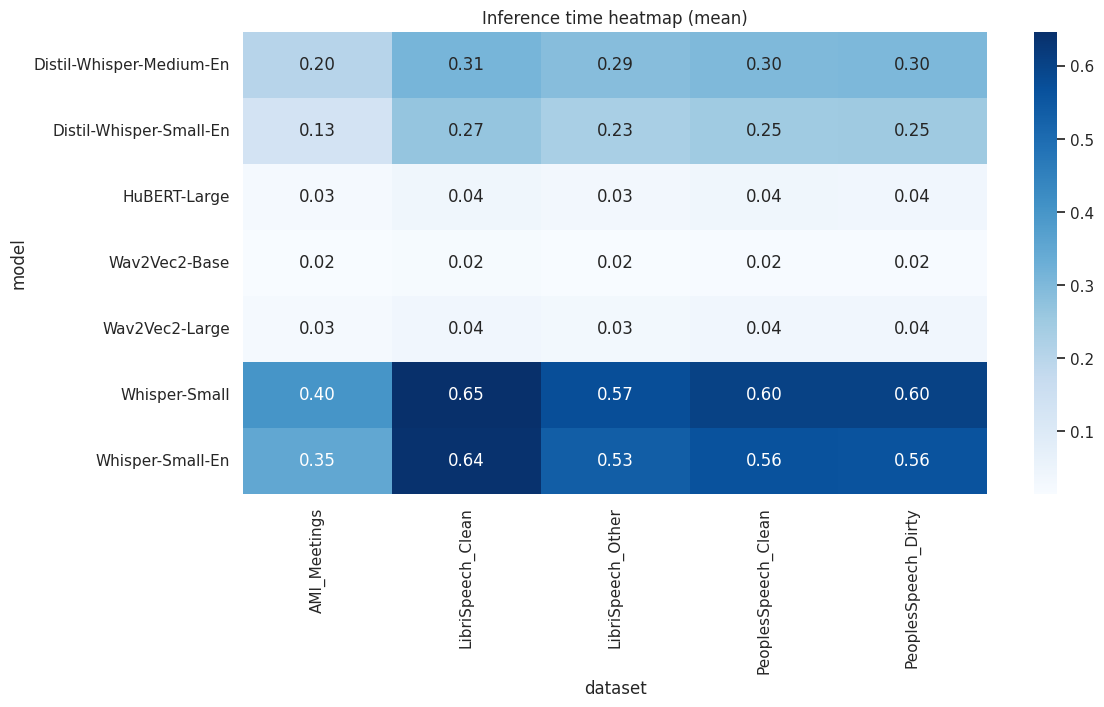

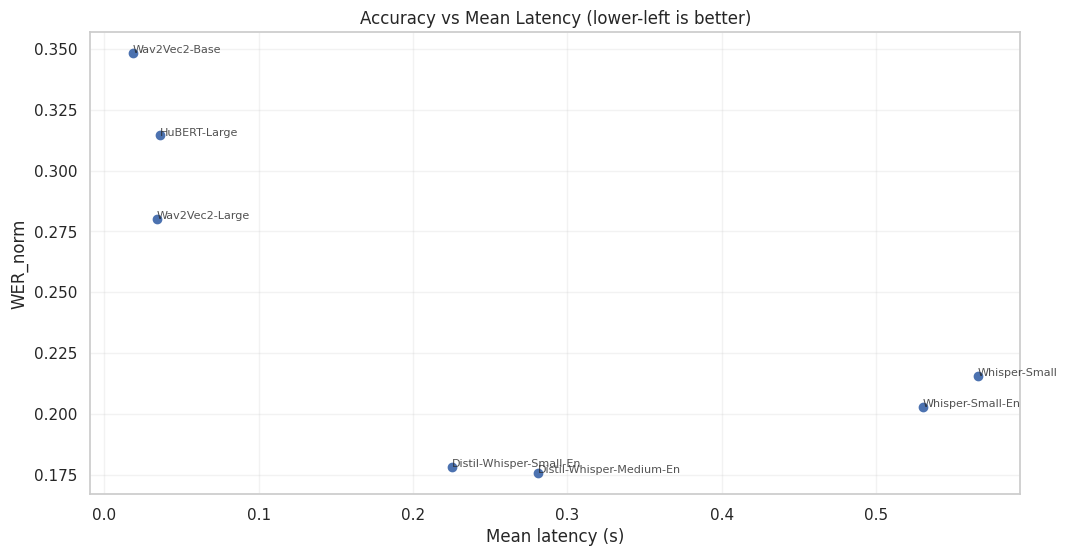

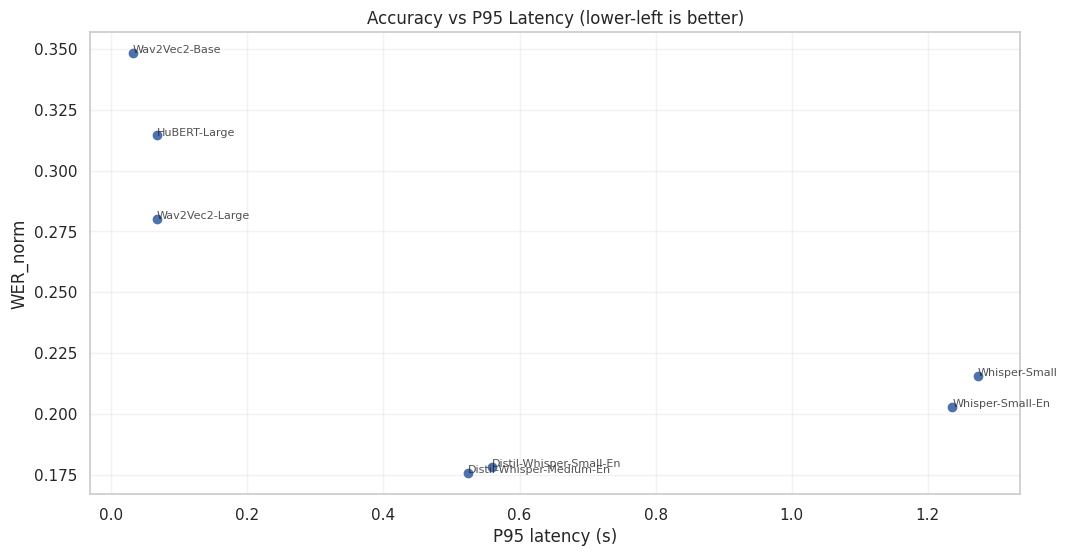

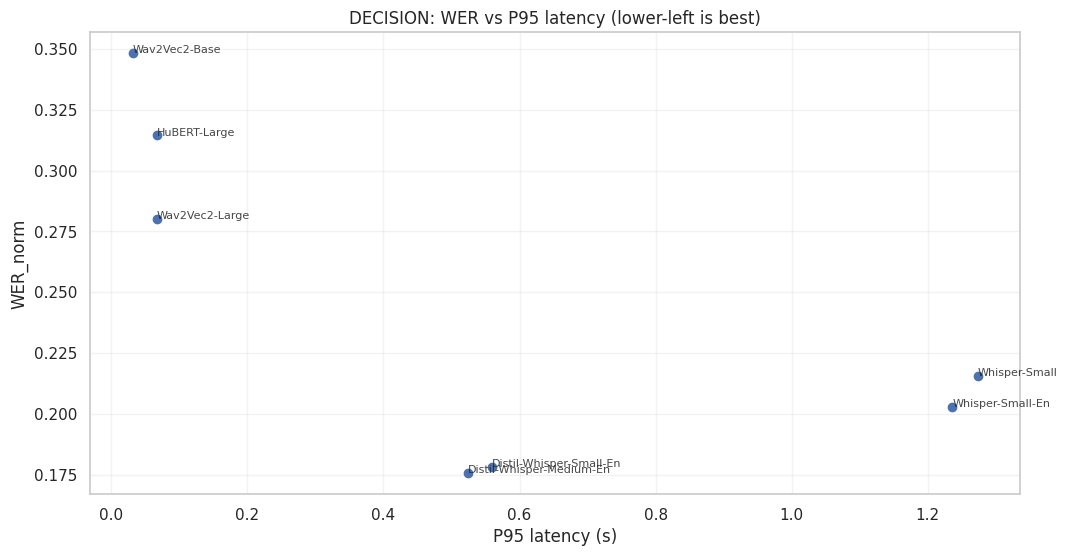

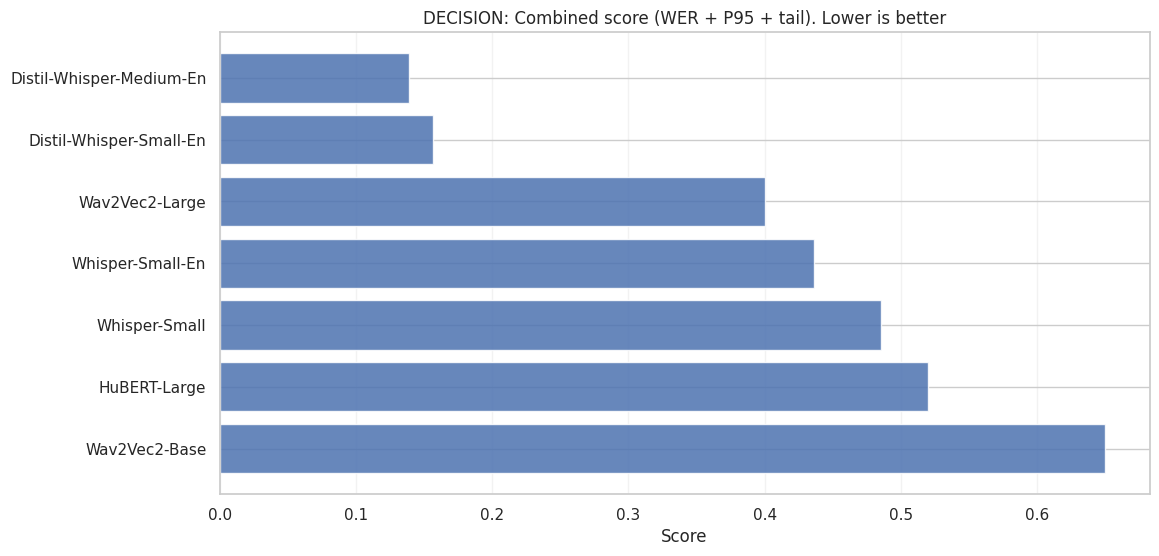

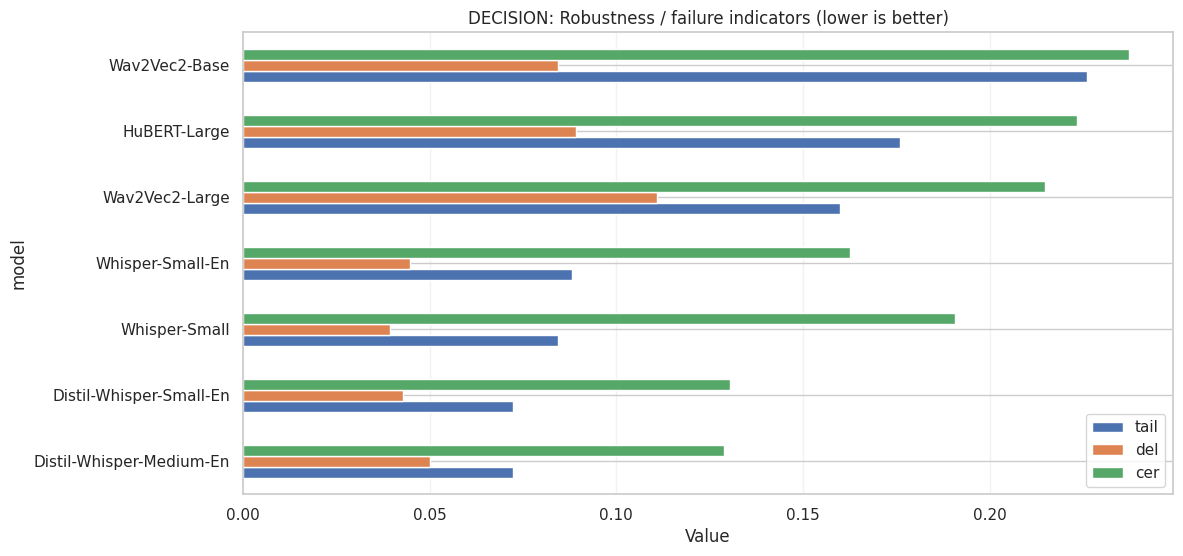

In [27]:
analyzer.display_summary_tables(df)

# Semantic categories
analyzer.plot_accuracy(df)
analyzer.plot_speed(df)
analyzer.plot_failure_modes(df)
analyzer.plot_robustness(df)
analyzer.plot_heatmaps(df)
analyzer.plot_tradeoffs(df)

# Decision plots last
analyzer.plot_decision_plots(df)

# 9. Detailed Errors Table


In [28]:
ERROR_MODEL = "Wav2Vec2-Large"        # e.g. "Whisper-Small" or "ALL"
ERROR_ROWS_LIMIT = 30      # how many rows to show
ERROR_MIN_WER = 0.20       # show only rows with wer_norm >= this (set to 0 to disable)

In [29]:
display(HTML("<h5>❌ Worst Errors (limited)</h5>"))

cols = [
    "model","dataset","language",
    "reference","transcript",
    "wer_norm","cer","time_s","peak_mem_mb",
]
existing_cols = [c for c in cols if c in df.columns]

df_err = df[existing_cols].copy()
df_err["wer_norm"] = pd.to_numeric(df_err.get("wer_norm"), errors="coerce")

# filter by model (optional)
if ERROR_MODEL != "ALL" and "model" in df_err.columns:
    df_err = df_err[df_err["model"] == ERROR_MODEL]

df_err = (
    df_err[df_err["wer_norm"].fillna(0) >= ERROR_MIN_WER]
    .sort_values("wer_norm", ascending=False)
    .head(ERROR_ROWS_LIMIT)
)

display(
    df_err.style
      .background_gradient(cmap="RdYlGn_r", subset=["wer_norm"] if "wer_norm" in df_err.columns else None)
      .format({"wer_norm": "{:.3f}", "cer": "{:.3f}", "time_s": "{:.2f}", "peak_mem_mb": "{:.1f}"}, na_rep="—")
      .set_properties(**{"white-space": "pre-wrap", "max-width": "300px"},
                      subset=[c for c in ["reference","transcript"] if c in df_err.columns])
)

,model,dataset,language,reference,transcript,wer_norm,cer,time_s,peak_mem_mb
3454,Wav2Vec2-Large,AMI_Meetings,en,SO,I BEGAN TO FELT IKE ISI,6.000,11.000,0.03,1316.7
3289,Wav2Vec2-Large,PeoplesSpeech_Clean,en,yeah,E GOUT TO BE CAREFUL,5.000,4.500,0.02,1313.3
3389,Wav2Vec2-Large,PeoplesSpeech_Dirty,en,yeah,E GOUT TO BE CAREFUL,5.000,4.500,0.02,1313.3
3451,Wav2Vec2-Large,AMI_Meetings,en,OKAY,LIKE IT,2.000,1.500,0.03,1312.8
3477,Wav2Vec2-Large,AMI_Meetings,en,ALRIGHT,ARE THEY,2.000,0.857,0.03,1312.8
3418,Wav2Vec2-Large,AMI_Meetings,en,THAT'S COOL,SCO,1.000,0.700,0.03,1313.5
3260,Wav2Vec2-Large,PeoplesSpeech_Clean,en,air sealing first,OA FOR,1.000,0.765,0.02,1314.1
3280,Wav2Vec2-Large,PeoplesSpeech_Clean,en,hot air rises,AS HEAT,1.000,0.846,0.02,1313.3
3265,Wav2Vec2-Large,PeoplesSpeech_Clean,en,there's some buying groups for propane now,SONE BING GROOPS APPROACH,1.000,0.537,0.02,1313.7
3420,Wav2Vec2-Large,AMI_Meetings,en,HMM,,1.000,1.000,0.02,1312.6


# 10. Export (save CSVs)


In [30]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

output_path = os.path.join(OUTPUT_DIR, "asr_results.csv")
df.to_csv(output_path, index=False)
print(f"💾 Results saved to: {output_path}")

summary_path = os.path.join(OUTPUT_DIR, "asr_summary.csv")
summary_df = df.groupby(["model", "dataset", "language"]).agg({
    "wer_norm": ["mean", "std", "min", "max"],
    "wer_raw": ["mean", "std"],
    "cer": ["mean", "std"],
    "time_s": ["mean", "std"],
    "del_rate": ["mean"],
    "ins_rate": ["mean"],
    "sub_rate": ["mean"],
}).round(4)

summary_df.to_csv(summary_path)
print(f"💾 Summary saved to: {summary_path}")

print(f"\n📁 All outputs saved to: {OUTPUT_DIR}")



💾 Results saved to: data/results/asr_results.csv
💾 Summary saved to: data/results/asr_summary.csv

📁 All outputs saved to: data/results
